# Demonstrating Fog/Haze Perturbations

## Introduction
This notebook is part of the NRTK demonstration suite, demonstrating how perturbations can be applied and their impact measured via MAITE evaluation workflows.

## Layout
This notebook demonstrates how a particular condition (in this case, <b><i>fog or haze</i></b>), can affect an object detection model, and how that impact can be measured. The overall structure is:

- **Evaluation Guidance: Computing Mean Average Precision (mAP):**
    - An overview of the evaluation strategy.
- **Setup:**
    - Notebook initialization, loading the supporting Python code. If this is the first time you've run this notebook, this may take some time.
    - Loading the source image, which will be used throughout the notebook.
- **Image Perturbation Examples:**
    - The NRTK perturbation is demonstrated on the source image.
- **Baseline Detections:**
    - The object detection model is loaded and run on the unperturbed image. These will serve as \"ground truth\" for comparisons against the perturbed images.
 
At this point, we have the fundamental elements of our evaluation: the model, our reference image, and a mechanism for creating the perturbed test images. Next we adapt these elements to be used with the MAITE evaluation workflow:

- **Wrapping the Detection Model**
- **Wrapping the Reference Image as a Dataset**
- **Wrapping the Perturbation as Augmentation Objects**
- **Wrapping the Metrics**

After the evaluation elements have been wrapped, we can run the evaluation:

- **Preparing the Augmentations:**
    - We specify the range of perturbation values to evaluate and optionally specify which ones we'd like to visualize.
- **Evaluation of Augmented Data:**
    - Each augmentation is run through MAITE's evaluation workflow, computing the absolute mAP metric of the detector on the perturbed datasets.
- **Evaluation Analysis:**
    - We plot and discuss the mAP@50 metric from each of the perturbed images, as well as per-class and per-area results.

To run this notebook in Colab, use the link below:

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Kitware/nrtk/blob/main/docs/examples/maite/fog_haze.ipynb)

## Evaluation Guidance: Computing Mean Average Precision (mAP)

This notebook evaluates the robustness of an Object Detector when exposed to NRTK (Natural, Physics-based) perturbations, using mean Average Precision (mAP) as the performance metric. The baseline case, where no perturbations are applied (identity augmentation), typically yields an mAP close to 1.0 and serves as the reference point. Unlike standard evaluations that focus on whether the detector can correctly identify and localize objects, our goal here is to measure how well the detector maintains its performance under realistic perturbations. 

By comparing the absolute mAP scores of the baseline against perturbed datasets, we can assess the detector's sensitivity to environmental variations and quantify its robustness in generating reliable predictions beyond controlled conditions.

## Setup: Notebook Initialization
The next few cells import the Python packages used in the rest of the notebook.

```{note}
We are suppressing warnings within this notebook to reduce visual clutter for demonstration purposes. If any issues arise while executing this notebook, we recommend that the first cell is **not** executed so that any related warnings are shown.
```

In [1]:
from __future__ import annotations

# warning suppression
import warnings

warnings.filterwarnings("ignore")

```{important}
This notebook requires NRTK with the following extra(s):

- `maite`: MAITE library providing evaluation capability and interoperability with other JATIC tools

The next cell will install these extra(s). See [Installation](<project:/getting_started/installation.rst>) for alternatives.
```

In [2]:
%pip install -qU pip
print("Installing nrtk with required extras...")
%pip install -q "nrtk[maite]>=1.1.0"
print("Installing notebook-specific packages...")
%pip install -q matplotlib torchvision torchmetrics ultralytics

# ultralytics pulls in opencv-python (non-headless), which requires libGL and
# fails in headless environments (e.g. CI). Replace it with the headless variant.
print("Replacing opencv-python with headless variant...")
%pip uninstall -qy opencv-python opencv-python-headless
%pip install -q opencv-python-headless --no-cache-dir

print("Done!")

from nrtk.utils._extras import print_extras_status  # noqa: E402 - intentionally after %pip install

print_extras_status()

Note: you may need to restart the kernel to use updated packages.
Installing nrtk with required extras...


Note: you may need to restart the kernel to use updated packages.
Installing notebook-specific packages...


Note: you may need to restart the kernel to use updated packages.
Replacing opencv-python with headless variant...


Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.
Done!


Detected status of NRTK extras and their dependencies:



[albumentations]
  - nrtk-albumentations       ✗ missing

[diffusion]
  - torch                     ✓ 2.10.0
  - diffusers                 ✗ missing
  - accelerate                ✗ missing
  - Pillow                    ✓ 13.0.0
  - transformers              ✗ missing
  - protobuf                  ✗ missing

[graphics]
  - opencv-python             ✗ missing

[hcipy]
  - hcipy                     ✗ missing
  - scipy                     ✗ missing
  - xxhash                    ✗ missing

[headless]
  - opencv-python-headless    ✓ 5.1.0.95

[maite]
  - maite                     ✓ 0.10.5

[pillow]
  - Pillow                    ✓ 13.0.0

[pyav]
  - av                        ✓ 17.1.0

[pybsm]
  - pybsm                     ✗ missing

[skimage]
  - scikit-image              ✗ missing

[tools]
  - kwcoco                    ✗ missing
  - Pillow                    ✓ 13.0.0
  - click                     ✓ 8.5.1
  - fastapi                   ✗ missing
  - uvicorn                   ✗ missing
  - pyda

    https://nrtk.readthedocs.io/en/stable/



```{note}
**Colab users**: After setting up the environment, you may need to "Restart Runtime" in order to resolve package version conflicts (see the [README](https://github.com/Kitware/nrtk/blob/main/docs/examples/README.md#run-the-notebooks-from-colab) for more info).
```

In [3]:
import os
import urllib.request
from collections.abc import Sequence
from typing import Any

import numpy as np

# some initial imports
%matplotlib inline
%config InlineBackend.figure_format = "jpeg"  # Use JPEG format for inline visualizations

from matplotlib import pyplot as plt  # type: ignore
from PIL import Image

from nrtk.impls.perturb_image.environment import HazePerturber

## Setup: Source Image

In the next cell, we'll download and display a source image from the __[VisDrone](https://github.com/VisDrone/VisDrone-Dataset)__ dataset. The image will be cached in a local `data` subdirectory.

### A Note on Image Storage

Typically in ML workflows, batches of images are processed as tensors of the color channels. Both our perturber (NRTK) and object detector (YOLO) accept numpy `ndarray` objects, and we will use [matplotlib.imshow](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.imshow.html) to view them. The complication is that YOLO [expects the color channels to be in BGR](https://docs.ultralytics.com/modes/predict) order. If we naively view the same data YOLO runs inference on, the colors will be wrong; if we naively run inference on what we view, the detections will be wrong. (Our NRTK perturbation is agnostic to the channel order.)

In this notebook, we'll convert the channel order to BGR when we load, and convert back whenever we explicitly call `imshow`.


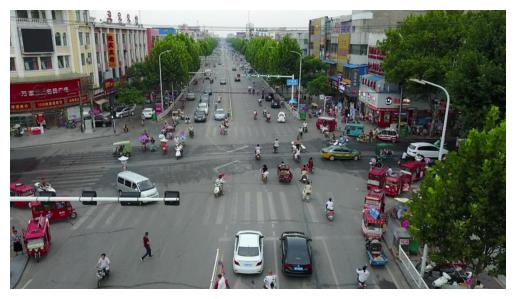

In [4]:
data_dir = "./data"
os.makedirs(data_dir, exist_ok=True)
img_path = os.path.join(data_dir, "visdrone_img.jpg")
if not os.path.isfile(img_path):
    url = "https://data.kitware.com/api/v1/item/623880f14acac99f429fe3ca/download"
    _ = urllib.request.urlretrieve(url, img_path)

img_pil = Image.open(img_path)
img_nd_bgr = np.asarray(img_pil)[
    :,
    :,
    ::-1,
]  # tip o' the hat to https://stackoverflow.com/questions/4661557/pil-rotate-image-colors-bgr-rgb
plt.figure()
plt.axis("off")

_ = plt.imshow(img_nd_bgr[:, :, ::-1])  # explicitly changing BGR to RGB for imshow

## NRTK Haze Perturbation: Examples and Guidance

The [Haze perturber](<project:/reference/api/_implementations/nrtk.impls.perturb_image.environment.HazePerturber.rst>) is set by the following parameters:

- `factor`: strength of haze applied to the image
- `sky_color`: optional sky color to use for weathering
- `depth_map`: optional depth map for adding haze

When a `depth_map` is not provided, the image is assumed to be planar and a default depth map of all ones, consistent with the input image dimensions, is used. When the `sky_color` is not provided, the average pixel color of the input image is used. When neither of these parameters are provided, the resulting image is effectively a lower contrast version of the input.

The ranges of these parameters are as follows:

- `factor >= 0`
- `0 <= sky_color[n] <= 255`
- `0.0 <= depth_map[x][y] <= 1.0`

For the purposes of this example notebook, we will change only the `factor` value. All other parameters will use the values from the original image. Note that a haze factor of `0.0` represents no change to the image.

We calculate a sample `depth_map` by generating a linear gradient with `1.0` at the top of the image and `0.2` at the bottom. Decreasing the `depth_map` from the top down indicates a horizon near the top of the image.

We obtain a `sky_color` by sampling the original image.

```{seealso}
For operational context, intended uses, and limitations of this perturbation, see [Haze](<project:/explanations/operational_risk_modules/haze.rst>).
```


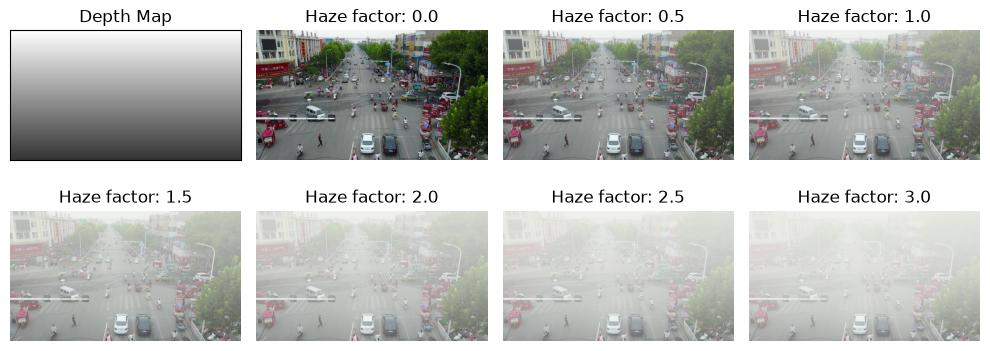

In [5]:
_, ax = plt.subplots(2, 4, figsize=(10, 4))

sky_color = [236, 240, 239]  # Taken from the visible sky at the top of the image
depth_map = np.zeros_like(img_nd_bgr, dtype="float")  # Depth map size = image size
depth_map[...] = np.linspace(1.0, 0.2, depth_map.shape[0])[..., None, None]  # Decreasing linspace
params = {
    "sky_color": sky_color,
    "depth_map": depth_map,
}

ax[0, 0].set_title("Depth Map")
ax[0, 0].imshow(depth_map)
ax[0, 0].axes.get_xaxis().set_visible(False)
ax[0, 0].axes.get_yaxis().set_visible(False)

for idx in range(1, 8):
    (row, col) = (int(idx / 4), idx % 4)
    factor = (idx - 1) / 2
    perturber = HazePerturber(factor=factor)
    ax[row, col].set_title(f"Haze factor: {factor}")
    ax[row, col].imshow(perturber(image=img_nd_bgr, **params)[0][:, :, ::-1])
    _ = ax[row, col].axis("off")

plt.tight_layout()

## Baseline Detections

In the next cell, we'll download a [YOLOv11](https://docs.ultralytics.com/models/yolo11#overview) model, compute object detections on the source image, and display the results. As discussed above, these detections will serve as the "ground truth" for comparisons against the perturbed images.

*Note that here, we're using YOLO's built-in visualization tool, which automatically adjusts for BGR / RGB order.*

In [6]:
# Import YOLO support
import ultralytics

ultralytics.checks()
print("Downloading model...")
model = ultralytics.YOLO("yolo11n.pt")
print("Computing baseline...")
baseline = model(img_nd_bgr)

Ultralytics 8.4.215 🚀 Python-3.13.11 torch-2.10.0+cu128 CUDA:0 (NVIDIA RTX A2000 8GB Laptop GPU, 7852MiB)


Setup complete ✅ (20 CPUs, 62.5 GB RAM, 691.8/914.7 GB disk)


Computing baseline...


0: 384x640 5 persons, 15 cars, 1 motorcycle, 2 trucks, 3.8ms


Speed: 22.5ms preprocess, 3.8ms inference, 9.7ms postprocess per image at shape (1, 3, 384, 640)


## MAITE Evaluation Workflow Preparation

We'll use the [MAITE Evaluation workflow](https://github.com/mit-ll-ai-technology/maite/blob/687706bf48efb9366aca5b9d588bafe2f460e644/src/maite/_internals/tasks/generic.py#L190) to evaluate the performance of the perturbed data against our baseline detections. We'll need to "wrap" our model, data, and perturbations into callable objects to pass to the `maite.tasks.evaluate` function:

- We'll wrap the **model** to make predictions on input data when called.

- The wrapped **dataset** will return our test image when called. Note that this will be the original, unperturbed image; we'll apply our perturbations via the **augmentation** object, which applies the perturbation to the image inside the evaluation.

- Finally, the **metric** object will define our precise scoring methodology.

The evaluation workflow in this notebook is slightly unusual. Typical ML workflows apply many different augmentations / perturbations to much larger datasets, and only call `evaluate` once to get a statistical view of performance. Since the goal of this notebook is to drill down into how perturbation affects performance, we've essentially flipped the process, calling `evaluate` (and thus our wrapped objects) many times, once per loop on our single image perturbed to a known degree, and then observing how the metrics respond.

### Some Helper Classes

The following cell adds two classes to allow us to use YOLO detections with the MAITE evaluation workflow:

1. The `YOLODetectionTarget` helper class that stores the bounding boxes, label indices, and confidence scores for a single image's detections.

2. The `MaiteYOLODetection` adapter class that conforms to the MAITE [Object Detection Dataset](https://github.com/mit-ll-ai-technology/maite/blob/687706bf48efb9366aca5b9d588bafe2f460e644/src/maite/_internals/protocols/object_detection.py#L86) protocol by providing the `__len__` and `__getitem__` methods. The returned item is a tuple of (image, `YOLODetectionTarget`, metadata-dictionary).

In [7]:
from dataclasses import dataclass

import torch
from maite.protocols.object_detection import DatumMetadataType

from nrtk.interop._maite.datasets import MAITEObjectDetectionDataset

##
## Helper class for containing the boxes, label indices, and confidence scores.
##


@dataclass
class YOLODetectionTarget:
    """A helper class to represent object detection results in the format expected by YOLO-based models.

    Attributes:
        boxes (torch.Tensor): A tensor containing the bounding boxes for detected objects in
            [x_min, y_min, x_max, y_max] format.
        labels (torch.Tensor): A tensor containing the class labels for the detected objects.
            These may be floats for compatibility with specific datasets or tools.
        scores (torch.Tensor): A tensor containing the confidence scores for the detected objects.
    """

    boxes: torch.Tensor
    labels: torch.Tensor
    scores: torch.Tensor


##
## Prepare results for ingestion into maite dataset by puttin them into detection object
## Images must be channel first (c, h, w) in maite dataset objects
##
imgs = [np.transpose(img_nd_bgr, (2, 0, 1))]
dets = []
metadata: list[DatumMetadataType] = [{"id": 0}]
for _detection in baseline:
    boxes = baseline[0].boxes.xyxy.cpu()
    labels = baseline[0].boxes.cls.cpu()  # note, these are floats, not ints
    scores = baseline[0].boxes.conf.cpu()

    dets.append(YOLODetectionTarget(boxes, labels, scores))

### (1) Wrapping the Detection Model

The first object we'll wrap will be the detection model. The cell below defines a class adapting YOLO for the [MAITE Object Detection Model](https://github.com/mit-ll-ai-technology/maite/blob/687706bf48efb9366aca5b9d588bafe2f460e644/src/maite/_internals/protocols/object_detection.py#L376) protocol. The `__call__` method runs the model on images in the batch and is called by the MAITE evaluation workflow later in the notebook.

In [8]:
import maite.protocols.object_detection as od
import ultralytics.models
from maite.protocols import ArrayLike, ModelMetadata


class MaiteYOLODetector:
    """A wrapper class for a YOLO model to simplify its usage with input batches and object detection targets.

    This class takes a YOLO model instance, processes input image batches, and converts predictions into
    `YOLODetectionTarget` instances.

    Attributes:
        _model (ultralytics.models.yolo.model.YOLO): The YOLO model instance used for predictions.

    Methods:
        __call__(batch):
            Processes a batch of images through the YOLO model and returns the predictions as
            `YOLODetectionTarget` instances.
    """

    def __init__(self, model: ultralytics.models.yolo.model.YOLO) -> None:
        """Initializes the MaiteYOLODetector with a YOLO model instance.

        Args:
            model (ultralytics.models.yolo.model.YOLO): The YOLO model to use for predictions.
        """
        self._model = model
        # Dummy model metadata type to pass type checking
        self.metadata = ModelMetadata(id="0")

    def __call__(self, batch: Sequence[ArrayLike]) -> Sequence[YOLODetectionTarget]:
        """Processes a batch of images using the YOLO model and converts the predictions to `YOLODetectionTarget`s.

        Args:
            batch (Sequence[ArrayLike]): A batch of images in (c, h, w) format (channel-first).

        Returns:
            Sequence[YOLODetectionTarget]: A list of YOLODetectionTarget instances containing the predictions for each
            image in the batch.
        """
        # Convert images to channel-last format (h, w, c) for YOLO model
        batch_transposed = [np.transpose(batch[i], (1, 2, 0)) for i in range(len(batch))]

        yolo_predictions = self._model(batch_transposed, verbose=False)
        return [
            YOLODetectionTarget(
                p.boxes.xyxy.cpu(),  # Bounding boxes in (x_min, y_min, x_max, y_max) format
                p.boxes.cls.cpu(),  # Class indices for the detected objects
                p.boxes.conf.cpu(),  # Confidence scores for the detections
            )
            for p in yolo_predictions
        ]


# create the wrapped model object
yolo_model: od.Model = MaiteYOLODetector(model)

### (2) Wrapping the Dataset

MAITE pairs images and their reference detections (aka targets, ground truth) into **datasets**. Typical ML workflows have many images per dataset; when these do not all fit in memory simultaneously, a *dataloader* object is used which can page images and annotations in from disk. For this notebook, however, each invocation of `evaluate` will use the same single-image dataset (our reference image with its baseline detections.)

In [9]:
# our single image, its baseline detections, and metadata dictionary
# switch image to channel first
single_image_dataset: od.Dataset = MAITEObjectDetectionDataset(
    imgs=imgs,
    dets=dets,
    datum_metadata=metadata,
    dataset_id="visdrone_ex",
)

### (3) Wrapping the Perturbations as Augmentations

The `evaluate` function will perturb the image from the dataset using instances of the class defined below, one instance per perturbation value. Note that the object doesn't perform any augmentations until called by the `evaluate` workflow.

In [10]:
from nrtk.interop import MAITEObjectDetectionAugmentation

perturber = HazePerturber(factor=0.0)
identity_augmentation = MAITEObjectDetectionAugmentation(augment=perturber, augment_id="identity")

### (4) Wrapping the Metrics

We'll compare the detections in each perturbed image to the unperturbed detections using the Mean Average Precision (mAP) metric from the `torchmetrics` package. The following cell creates a mAP metrics object, wraps it in a [MAITE Object Detection Metric](https://github.com/mit-ll-ai-technology/maite/blob/687706bf48efb9366aca5b9d588bafe2f460e644/src/maite/_internals/protocols/object_detection.py#L470) protocol-compatible class, and then creates an instance of this class, which will be called by `evaluate`.

This code is copied directly from the [MAITE object detection tutorial](https://github.com/mit-ll-ai-technology/maite/blob/main/examples/tutorials/torchvision_object_detection.ipynb) (with the exception of setting `class_metrics=True`.)

In [11]:
from maite.protocols import MetricMetadata
from torchmetrics import Metric as TorchMetric
from torchmetrics.detection.mean_ap import MeanAveragePrecision

##
## Create an instance of the MAP metric object
##

tm_metric = MeanAveragePrecision(
    box_format="xyxy",
    iou_type="bbox",
    iou_thresholds=[0.5],
    rec_thresholds=[0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
    max_detection_thresholds=[1, 10, 100],
    class_metrics=True,
    extended_summary=False,
    average="macro",
)

##
## This wrapper associates the MAP metric object with methods called by the evaluate
## workflow to accumulate detection data and compute the metrics.
##


class WrappedTorchmetricsMetric:
    """A wrapper class for a Torchmetrics metric designed to simplify its usage for object detection tasks.

    This class facilitates the conversion of object detection targets and predictions into the format
    expected by Torchmetrics metrics, allowing for easier integration with existing pipelines.

    Attributes:
        _tm_metric (Callable): The Torchmetrics metric to be wrapped, which takes lists of dictionaries
            containing torch.Tensor objects representing predictions and targets.

    Methods:
        to_tensor_dict(target):
            Converts an `ObjectDetectionTarget` into a dictionary format compatible with the Torchmetrics
            metric's `update` method.

        update(preds, targets):
            Updates the wrapped Torchmetrics metric with batches of predictions and targets in their native format.

        compute():
            Computes the final metric values using the wrapped Torchmetrics metric.

        reset():
            Resets the state of the wrapped Torchmetrics metric.
    """

    def __init__(
        self,
        tm_metric: TorchMetric,
    ) -> None:
        """Initializes the WrappedTorchmetricsMetric with the given Torchmetrics metric.

        Args:
            tm_metric (Callable): A Torchmetrics metric instance that expects predictions and targets as lists of
                dictionaries containing torch.Tensor objects.
        """
        self._tm_metric = tm_metric
        # Dummy metric metadata type to pass type checking
        self.metadata = MetricMetadata(id="0")

    @staticmethod
    def to_tensor_dict(target: od.ObjectDetectionTarget) -> dict[str, torch.Tensor]:
        """Converts an ObjectDetectionTarget into a dictionary format compatible with the Torch's `update` method.

        Args:
            target (od.ObjectDetectionTarget): An object detection target instance containing boxes, labels, and scores.

        Returns:
            dict[str, torch.Tensor]: A dictionary with keys `boxes`, `scores`, and `labels`, each mapping to a tensor.
        """
        return {
            "boxes": torch.as_tensor(target.boxes),
            "scores": torch.as_tensor(target.scores),
            "labels": torch.as_tensor(target.labels).type(torch.int64),
        }

    def update(
        self,
        preds: Sequence[od.TargetType],
        targets: Sequence[od.TargetType],
        _: Sequence[od.DatumMetadataType],
    ) -> None:
        """Updates the wrapped Torchmetrics metric with the given predictions and targets.

        Args:
            preds (Sequence[od.TargetType]): A batch of predictions in the format expected by the Torchmetrics metric.
            targets (Sequence[od.TargetType]): A batch of targets in the format expected by the Torchmetrics metric.
        """
        preds_tm = [self.to_tensor_dict(pred) for pred in preds]
        targets_tm = [self.to_tensor_dict(tgt) for tgt in targets]
        self._tm_metric.update(preds_tm, targets_tm)

    def compute(self) -> dict[str, Any]:
        """Computes and returns the final metric values using the wrapped Torchmetrics metric.

        Returns:
            dict[str, Any]: A dictionary containing the computed metric values.
        """
        return self._tm_metric.compute()

    def reset(self) -> None:
        """Resets the state of the wrapped Torchmetrics metric, clearing any accumulated data."""
        self._tm_metric.reset()


##
## This is our instance variable that can compute the MAP metrics.
##

mAP_metric: od.Metric = WrappedTorchmetricsMetric(tm_metric)  # noqa: N816

## Running the Evaluation

We now have all the wrappings required to evaluate our range of perturbations:
- The `yolo_model` object, wrapping the YOLO model
- The `single_image_dataset` object, providing our source image and its baseline detections
- The `augmentation` object, which when instantiated, applies a single perturbation value to its input
- The `mAP_metrics` object, defining the metrics to compute at each perturbation value

### Evaluation Sanity Check: Ground Truth Against Itself

Here we quickly check the evaluation workflow by creating an *identity augmentation* (with a haze factor of 0.0, leaving the image unchanged) and scoring it. The detections should also be unchanged from the baseline and thus give an mAP of 1.0.

In [12]:
from maite.tasks import evaluate

# call the model for each image in the dataset (in this case, just the source image),
# scoring the resulting detections against those from the dataset
sanity_check_results, _, _ = evaluate(
    model=yolo_model,
    dataset=single_image_dataset,
    augmentation=identity_augmentation,
    metric=mAP_metric,
)

print("Sanity check: overall mAP (should be 1.0):", sanity_check_results["map"].item())

Sanity check: overall mAP (should be 1.0): 1.0


### Preparing the Data

Now we'll prepare the augmentation instances for evaluation. In the cell below, you can set three parameters for sweeping the set of perturbation values:
- **SWEEP_LOW**: the minimum perturbation value (must be >= 0)
- **SWEEP_HIGH**: the maximum perturbation value
- **SWEEP_COUNT**: how many perturbations to generate

You can also optionally select perturbations to visualize:
- **VISUALIZATION_INDICES**: a list of perturbation indices *p*, 0 <= *p* < sweep_count. These instances will be rendered along with their corresponding detections.

In [13]:
SWEEP_LOW = 0.0
SWEEP_HIGH = 4.0
SWEEP_COUNT = 30
VISUALIZATION_INDICES = [0, 5, 9]

##
## end user-settable parameters
##

perturbation_values = np.linspace(SWEEP_LOW, SWEEP_HIGH, SWEEP_COUNT, endpoint=True)
augmentations = [
    MAITEObjectDetectionAugmentation(augment=HazePerturber(factor=p), augment_id=str(idx))
    for idx, p in enumerate(perturbation_values)
]

print(f"Generated {len(augmentations)} perturbation augmentations")

Generated 30 perturbation augmentations


### Calling Evaluate on the Augmented Data

We loop over all the augmentations, calling `evaluate` on each one and building up a list of resulting metrics for analysis.

Any augmentation indices specified above will be rendered in this step.

Perturbation #0: haze factor 0.0



0: 384x640 5 persons, 15 cars, 1 motorcycle, 2 trucks, 3.7ms


Speed: 0.8ms preprocess, 3.7ms inference, 0.7ms postprocess per image at shape (1, 3, 384, 640)


Perturbation #5: haze factor 0.6896551724137931


0: 384x640 6 persons, 7 cars, 3 trucks, 1 traffic light, 3.7ms


Speed: 0.8ms preprocess, 3.7ms inference, 0.7ms postprocess per image at shape (1, 3, 384, 640)


Perturbation #9: haze factor 1.2413793103448276


0: 384x640 6 persons, 9 cars, 2 trucks, 1 traffic light, 3.7ms


Speed: 1.0ms preprocess, 3.7ms inference, 0.7ms postprocess per image at shape (1, 3, 384, 640)


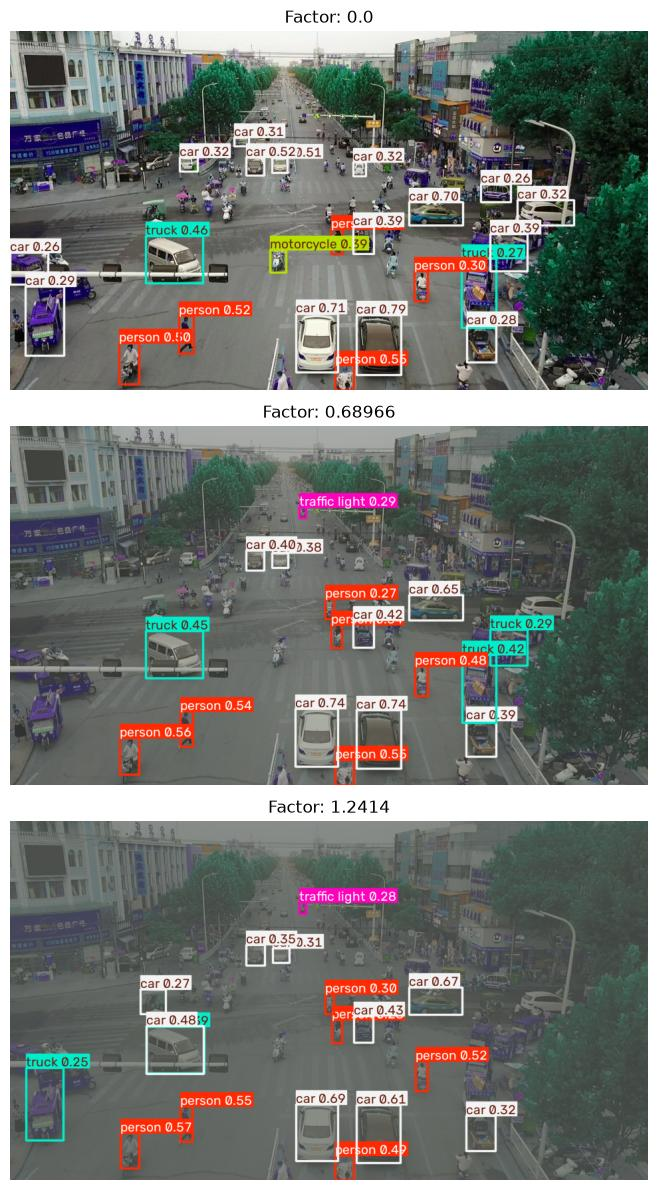

In [14]:
perturbed_metrics = []
_, ax = plt.subplots(len(VISUALIZATION_INDICES), figsize=(30, 12))
for idx, a in enumerate(augmentations):
    # reset the metric object for each dataset
    mAP_metric.reset()
    result, _, _ = evaluate(model=yolo_model, dataset=single_image_dataset, augmentation=a, metric=mAP_metric)
    perturbed_metrics.append(result)

    if idx in VISUALIZATION_INDICES:
        # quickest way is to re-evaluate
        factor = a.augment.get_config()["factor"]
        print(f"Perturbation #{idx}: haze factor {factor}")
        datum = single_image_dataset[0]
        batch = ([datum[0]], [datum[1]], [datum[2]])
        # Extract the image from the augmentation and switch it to channel last
        aug = np.transpose(a(batch)[0][0], (1, 2, 0))
        # Plot image
        ax_idx = VISUALIZATION_INDICES.index(idx)
        ax[ax_idx].imshow(model(aug)[0].plot())
        ax[ax_idx].set_title(f"Factor: {factor:0.5}")
        _ = ax[ax_idx].axis("off")
plt.tight_layout()

## Evaluation Analysis

Now we can plot how the metrics (for example, mAP @ IoU=50) vary with perturbation level, keeping in mind these are the mAP scores compared against the detections in the unperturbed image.


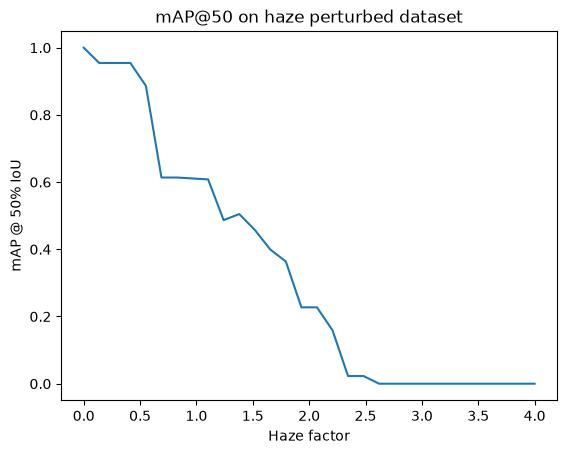

In [15]:
map50_list = [m["map_50"].item() for m in perturbed_metrics]
plt.title("mAP@50 on haze perturbed dataset")
plt.xlabel("Haze factor")
plt.ylabel("mAP @ 50% IoU")
_ = plt.plot(perturbation_values, map50_list)

### Evaluation Interpretation

**General things to know about mAP calculation**:
- The mAP metric calculation does not take into account the images that do not have any detection or any ground truth. In such cases, it returns the default initialization value, -1. It means it couldn't compute the metric. (Source: [link](https://github.com/Lightning-AI/torchmetrics/issues/1184#issuecomment-1589210748)). Hence, in this notebook example, we clip values to a range of `[0, 1]`.
- When having images with no ground truth, the order of those images in the batch can change the mAP calculation. To be more precise, if empty images are at the end of the batch, they will be ignored in the computation. But the empty images that are placed before the last non-empty image are taken into account. (Source: [link](https://github.com/Lightning-AI/torchmetrics/issues/1774#issuecomment-1590681234)).

The metric shown, mAP@50, is the average precision of detections across all classes when the bounding box IoU is at least 0.5 (for more details, [see here](https://lightning.ai/docs/torchmetrics/stable/detection/mean_average_precision.html)). The mAP value appears to decrease almost linearly as the haze factor increases. It reaches zero when the haze factor is around 2.5.

Viewing the object detection boundaries in the perturbed image highlights the fact that objects closer to the foreground are more easily detected when using the haze perturber. With our approximated depth map input, this means any object closer to the bottom of the image.

### Additional Plots

For further insight, we can plot the mAP per class:

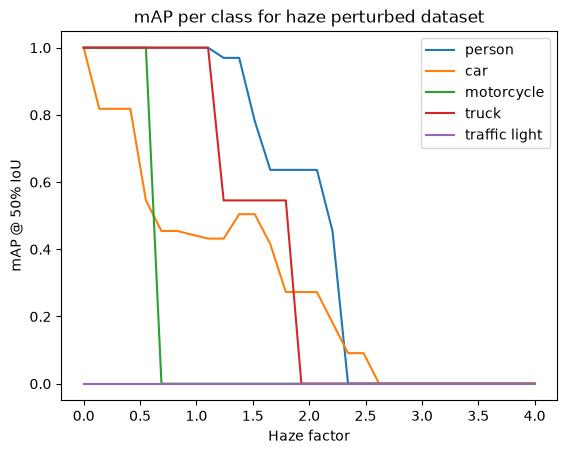

In [16]:
#
# Each instance of the metrics object has, potentially, a different set of observed classes.
# Loop through them to accumulate a unified set of classes to ensure consistent plotting across
# all thresholds.
#

unified_classes = set()
for m in perturbed_metrics:
    for class_idx in m["classes"].tolist():
        unified_classes.add(class_idx)

#
# dictionary of class_idx -> list of per-class mAP, or 0 if not present at that threshold
#

class_mAP = {class_idx: [] for class_idx in unified_classes}  # noqa: N816

#
# populate the lists across the perturbation values
#

for m in perturbed_metrics:
    this_perturbation_classes = m["classes"].tolist()
    for class_idx in unified_classes:
        if class_idx in this_perturbation_classes:
            # the index of the class in this individual metric instance
            this_class_idx = this_perturbation_classes.index(class_idx)
            class_map_value = m["map_per_class"][this_class_idx].item()
            # Clip value to 0 if negative
            if class_map_value < 0:
                class_mAP[class_idx].append(0)
            else:
                class_mAP[class_idx].append(m["map_per_class"][this_class_idx].item())
        else:
            class_mAP[class_idx].append(0)

#
# plot
#

plt.title("mAP per class for haze perturbed dataset")
plt.xlabel("Haze factor")
plt.ylabel("mAP @ 50% IoU")
for class_idx, class_mAP_list in class_mAP.items():  # noqa: N816
    plt.plot(perturbation_values, class_mAP_list, label=baseline[0].names[class_idx])
plt.legend()
plt.show()

The above plots show several interesting results:

- Each class experiences a significant decrease in performance as the haze factor increases, though at different rates.
- The motorcycle class shows initial robustness to low haze factors but experiences a rapid performance drop around a haze factor of 0.5.
- The person class demonstrates the most robustness to haze perturbations across the tested range.
- The car class shows a more gradual decline in detection accuracy, which can be attributed to the positioning of several cars near the bottom of the image (foreground) where they are less affected by the depth-based haze simulation.
- All classes eventually reach near-zero performance at higher haze factors, demonstrating the significant impact of atmospheric conditions on object detection.


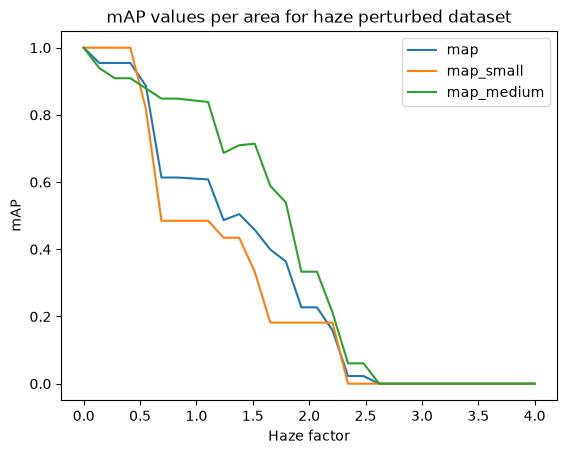

In [17]:
plt.title("mAP values per area for haze perturbed dataset")
plt.xlabel("Haze factor")
plt.ylabel("mAP")
for k in ("map", "map_small", "map_medium"):
    plt.plot(perturbation_values, [m[k].item() if m[k].item() >= 0 else 0 for m in perturbed_metrics], label=k)
plt.legend()
plt.show()

The `map` line covers all sizes; `map_small` and `map_medium` are the mean average precision for objects (smaller than 32^2 pixels, between 32^2 and 96^2 pixels) in area, respectively. (There are no detections in the `map_large` category.) (Here, the mAP value is averaged over a **range** of IoU thresholds, between 0.5 and 0.95.) We see that medium objects, regardless of class, are generally much more robust to more haze perturbations than small ones.


## End of Notebook